# Applying the pipeline to a real crowd — the Mall dataset

`TBPR_finetune.ipynb` trained the model on clean pedestrian crops. Here the whole system runs on footage it never saw: the **Mall dataset** (Chen et al., BMVC 2012), one fixed camera over a busy shopping-mall floor.

| | |
|---|---|
| Frames | 2,000 · 640×480 · under 2 frames per second |
| Labels | a point on every head inside the floor region: 62,315 in total, 13–53 per frame |
| Identity labels | none, so grounding is judged by looking at the chosen crops |

Two questions:
1. **Does stage 1 see the people?** The text model can only pick among the boxes that YOLO finds. Every head point is matched to at most one person box, which gives precision, recall and counting error.
2. **Does stage 2 pick the right person in a crowd?** Four descriptions of shoppers who appear in the clip are run through the full tracker, and the boxed person is shown.

## 1 · Setup

In [1]:
import sys
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO

from tbpr import INK, INK_2, PLOT_RC, SERIES, SURFACE, HeadMatch, MallFrames, boxes_in_roi, load_mall, match_heads

sys.path.insert(0, "demo")
from track_person import (Settings, TrackState, best_match, crop_person, detect_people, encode_crops, encode_query,
                          full_body_ids, load_embedder, score_tracks, stale_detections, update_states)

MALL_ROOT: Path = Path("mall_dataset")
OUT: Path = Path("outputs/mall")
OUT.mkdir(parents=True, exist_ok=True)
DETECTOR: str = "models/yolo26s.pt"
MODEL: str = "models/embeddinggemma2-rstpreid"
TOP_FRAC: float = 0.45     # a head must sit in the top 45% of its box
HEAD_FRAC: float = 0.08    # expected head point: 8% of the box height below its top
plt.rcParams.update(PLOT_RC)

/home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2 · Data

2000 frames, 62,315 head points, 13–53 per frame (mean 31.2)


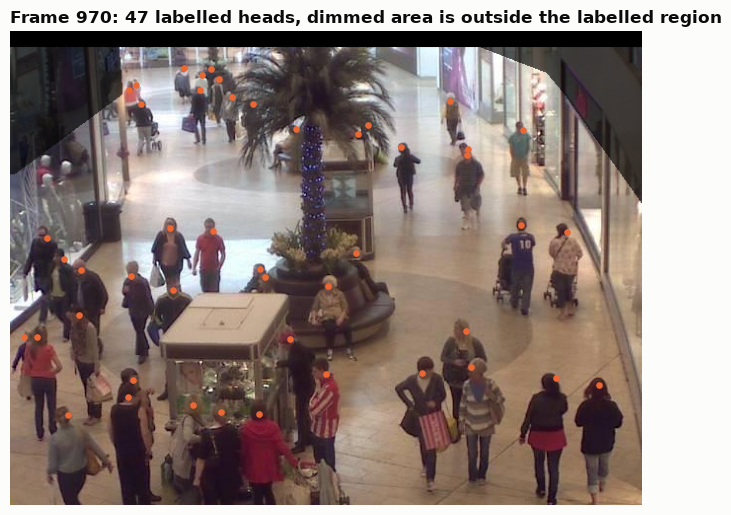

In [2]:
mall: MallFrames = load_mall(MALL_ROOT)
counts: np.ndarray = np.array([len(h) for h in mall.heads])
print(f"{len(mall.frame_paths)} frames, {counts.sum():,} head points, {counts.min()}–{counts.max()} per frame (mean {counts.mean():.1f})")

frame_idx = 969
img = cv2.cvtColor(cv2.imread(str(mall.frame_paths[frame_idx])), cv2.COLOR_BGR2RGB)
shade = img.copy(); shade[~mall.roi] = (shade[~mall.roi] * 0.35).astype(np.uint8)
fig, ax = plt.subplots(figsize=(7, 5.25))
ax.imshow(shade); ax.scatter(mall.heads[frame_idx][:, 0], mall.heads[frame_idx][:, 1], s=14, c=SERIES[1])
ax.set_title(f"Frame {frame_idx + 1}: {counts[frame_idx]} labelled heads, dimmed area is outside the labelled region")
ax.axis("off"); fig.tight_layout(); plt.show()

## 3 · Stage 1: person detection
YOLO runs once per frame at two input sizes with a low confidence floor (0.1). The confidence threshold is then applied afterwards, so the sweep costs no extra passes. A box counts only when its expected head point falls inside the labelled region, because people outside it have no labels.

In [3]:
@dataclass(frozen=True)
class FrameBoxes:
    boxes: np.ndarray   # (N, 4) x1, y1, x2, y2
    conf: np.ndarray    # (N,)


def detect_all(detector: YOLO, paths: list[Path], imgsz: int, batch: int) -> list[FrameBoxes]:
    out: list[FrameBoxes] = []
    for s in range(0, len(paths), batch):
        for r in detector.predict([str(p) for p in paths[s:s + batch]], classes=[0], conf=0.1, imgsz=imgsz, verbose=False):
            out.append(FrameBoxes(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()))
    return out


detector = YOLO(DETECTOR)
detections: dict[int, list[FrameBoxes]] = {sz: detect_all(detector, mall.frame_paths, sz, 32) for sz in (640, 1280)}

In [4]:
def kept(fb: FrameBoxes, conf: float) -> np.ndarray:
    b = fb.boxes[fb.conf >= conf]
    return b[boxes_in_roi(b, mall.roi, HEAD_FRAC)]


def evaluate(dets: list[FrameBoxes], conf: float) -> dict[str, float]:
    matches: list[HeadMatch] = [match_heads(kept(fb, conf), h, TOP_FRAC, HEAD_FRAC) for fb, h in zip(dets, mall.heads)]
    tp, fp, fn = (sum(getattr(m, k) for m in matches) for k in ("tp", "fp", "fn"))
    pred = np.array([m.tp + m.fp for m in matches])
    return {"precision": 100 * tp / (tp + fp), "recall": 100 * tp / (tp + fn), "F1": 100 * 2 * tp / (2 * tp + fp + fn),
            "count MAE": float(np.abs(pred - counts).mean()), "count RMSE": float(np.sqrt(((pred - counts) ** 2).mean()))}


rows = [{"imgsz": sz, "conf": c, **evaluate(detections[sz], c)} for sz in (640, 1280) for c in (0.25, 0.4, 0.5)]
results = pd.DataFrame(rows)
results.to_csv(OUT / "results_detection.csv", index=False)
results.round(2)

,imgsz,conf,precision,recall,F1,count MAE,count RMSE
0,640,0.25,96.52,48.49,64.55,15.50,16.58
1,640,0.40,97.70,39.00,55.74,18.72,19.90
2,640,0.50,98.18,32.89,49.27,20.72,21.93
3,1280,0.25,92.45,66.29,77.22,8.81,9.49
4,1280,0.40,95.86,59.53,73.44,11.81,12.51
5,1280,0.50,97.11,54.32,69.67,13.73,14.49


### Where are people missed?
Recall is split by how far down the frame the head is. Near the top of the frame people are far from the camera and only a few pixels tall.

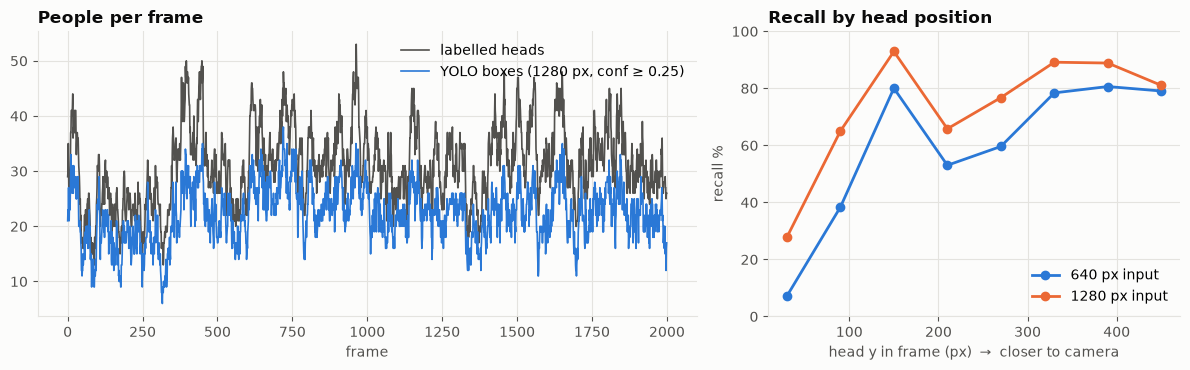

In [5]:
BANDS: np.ndarray = np.arange(0, 481, 60)


def recall_by_row(dets: list[FrameBoxes], conf: float) -> np.ndarray:
    hit = np.zeros(len(BANDS) - 1); tot = np.zeros(len(BANDS) - 1)
    for fb, h in zip(dets, mall.heads):
        m = match_heads(kept(fb, conf), h, TOP_FRAC, HEAD_FRAC)
        band = np.clip(np.digitize(h[:, 1], BANDS) - 1, 0, len(BANDS) - 2)
        np.add.at(tot, band, 1); np.add.at(hit, band, m.gt_hit)
    return 100 * hit / np.maximum(tot, 1)


best = results.loc[results["F1"].idxmax()]
best_sz, best_conf = int(best["imgsz"]), float(best["conf"])
pred_counts = np.array([len(kept(fb, best_conf)) for fb in detections[best_sz]])

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
a.plot(counts, color=INK_2, lw=1.2, label="labelled heads")
a.plot(pred_counts, color=SERIES[0], lw=1.2, label=f"YOLO boxes ({best_sz} px, conf ≥ {best_conf})")
a.set_title("People per frame"); a.set_xlabel("frame"); a.legend(loc="upper right")
centres = (BANDS[:-1] + BANDS[1:]) / 2
for i, sz in enumerate((640, 1280)):
    b.plot(centres, recall_by_row(detections[sz], best_conf), marker="o", color=SERIES[i], label=f"{sz} px input")
b.set_title("Recall by head position"); b.set_xlabel("head y in frame (px)  →  closer to camera"); b.set_ylabel("recall %")
b.set_ylim(0, 100); b.legend(loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "results_detection.png", dpi=160, facecolor=SURFACE); plt.show()

## 4 · Stage 2: grounding a description in the crowd
The full tracker from `demo/track_person.py` runs over the 2,000 frames with its default settings: refresh every 10 frames, EMA 0.3, threshold 0.45, and a minimum box height-to-width ratio of 1.2. All four descriptions are scored at once against the same tracks. For each description, the frame where its match scored highest is shown with the chosen box.

In [6]:
QUERIES: list[str] = [
    "a man in a red and white striped shirt",
    "a man in a red t-shirt and dark jeans",
    "a woman in a red coat",
    "a woman in a light pink top and black trousers",
]
SETTINGS = Settings(refresh=10, ema=0.3, threshold=0.45, pad=0.05, forget=60, min_aspect=1.2, conf=0.4, imgsz=640, batch=32)


@dataclass(frozen=True)
class Grounded:
    frame: int
    score: float
    box: tuple[int, int, int, int]
    others: list[tuple[int, int, int, int]]


embedder = load_embedder(MODEL, 70)
tracker = YOLO(DETECTOR)
qvecs = np.stack([encode_query(embedder, q) for q in QUERIES])
states: dict[int, TrackState] = {}
best_hit: dict[str, Grounded] = {}
matched_frames: dict[str, int] = {q: 0 for q in QUERIES}
for i, path in enumerate(mall.frame_paths):
    frame = cv2.imread(str(path))
    dets = detect_people(tracker, frame, SETTINGS.conf, SETTINGS.imgsz)
    todo = stale_detections(dets, states, i, SETTINGS.refresh)
    embs = (encode_crops(embedder, [crop_person(frame, d.box, SETTINGS.pad) for d in todo], SETTINGS.batch)
            if todo else np.zeros((0, qvecs.shape[1]), dtype=np.float32))
    states = update_states(states, dets, todo, embs, i, SETTINGS)
    eligible = full_body_ids(dets, SETTINGS.min_aspect)
    for q, v in zip(QUERIES, qvecs):
        scores = score_tracks(dets, states, v)
        t = best_match(scores, eligible, SETTINGS.threshold)
        if t is None:
            continue
        matched_frames[q] += 1
        if q not in best_hit or scores[t] > best_hit[q].score:
            box = next(d.box for d in dets if d.track_id == t)
            best_hit[q] = Grounded(i, scores[t], box, [d.box for d in dets if d.track_id != t])
pd.DataFrame([{"query": q, "best score": round(best_hit[q].score, 3), "best frame": best_hit[q].frame + 1,
               "frames with a match": matched_frames[q]} for q in QUERIES])

Loading weights:   0%|          | 0/624 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 624/624 [00:00<00:00, 11925.03it/s]

,query,best score,best frame,frames with a match
0,a man in a red and white striped shirt,0.724,789,375
1,a man in a red t-shirt and dark jeans,0.629,1917,378
2,a woman in a red coat,0.624,820,521
3,a woman in a light pink top and black trousers,0.600,1575,775


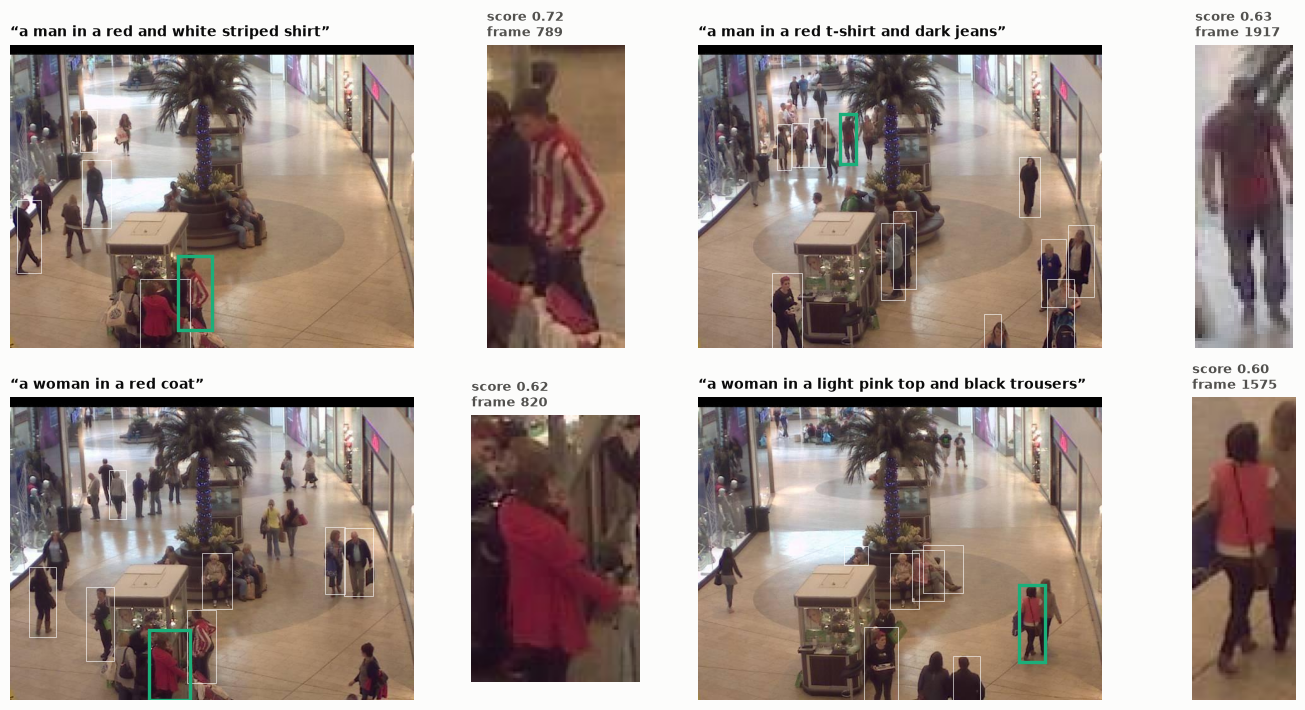

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7.2), gridspec_kw={"width_ratios": [3, 1, 3, 1]})
for k, q in enumerate(QUERIES):
    g = best_hit[q]
    img = cv2.cvtColor(cv2.imread(str(mall.frame_paths[g.frame])), cv2.COLOR_BGR2RGB)
    ax, cax = axes[k // 2, 2 * (k % 2)], axes[k // 2, 2 * (k % 2) + 1]
    ax.imshow(img)
    for x1, y1, x2, y2 in g.others:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", lw=0.6, alpha=0.7))
    x1, y1, x2, y2 = g.box
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=SERIES[2], lw=2.4))
    ax.set_title(f"“{q}”", fontsize=10); ax.axis("off")
    cax.imshow(np.asarray(crop_person(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), g.box, 0.1)))
    cax.set_title(f"score {g.score:.2f}\nframe {g.frame + 1}", fontsize=9, color=INK_2); cax.axis("off")
fig.tight_layout(); fig.savefig(OUT / "grounding_examples.png", dpi=160, facecolor=SURFACE); plt.show()

## 5 · Findings

**Stage 1 is the bottleneck in a dense crowd, not the text model.**
- At the demo's settings (640 px, confidence 0.4), YOLO is precise (97.7%), so almost every box is a real person. Recall is only **39%**, though, because far-away people near the top of the frame are 15–30 px tall, and people are hidden behind the kiosk and the palm tree.
- At **1280 px** input with confidence 0.25, recall rises to **66%**, F1 to **77%**, and the count error drops from 18.7 to **8.8 people per frame**, at the cost of about 4× the detector compute. For crowded scenes this is worth passing to the tracker as `--imgsz 1280 --conf 0.25`.
- Recall near the camera (head y > 300 px) is 80–90% at both sizes. The dip around y ≈ 200 px is the seating area around the palm tree, where people overlap.

**Stage 2 transfers.** The model was fine-tuned only on RSTPReid crops, yet it picks the described shopper out of 20–30 people. The four descriptions reach best scores of 0.60–0.72, all above the 0.45 threshold, and the boxed person is the right one in each example above. The failures are in what the detector never boxes: a person without a box cannot be chosen.